In [1]:

from pathlib import Path
import pandas as pd

data_dir = Path("../data")

monthly = pd.read_csv(
    data_dir / "measles_national_monthly.csv"
)

age = pd.read_csv(
    data_dir / "measles_national_age.csv"
)

annual = pd.read_csv(
    data_dir / "measles_national_annual.csv"
)

for name, df in [
    ("Monthly", monthly),
    ("Age groups", age),
    ("Annual", annual)
]:
    print(f"\n{'=' * 45}")
    print(name)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    print("\nMissing values:")
    print(df.isna().sum())

    print("\nFirst five rows:")
    display(df.head())



Monthly
Shape: (120, 6)
Columns: ['year', 'month_number', 'month', 'reported_cases', 'national_annual_population', 'monthly_cases_per_100k_annual_population']

Missing values:
year                                        0
month_number                                0
month                                       0
reported_cases                              0
national_annual_population                  0
monthly_cases_per_100k_annual_population    0
dtype: int64

First five rows:


,year,month_number,month,reported_cases,national_annual_population,monthly_cases_per_100k_annual_population
0,2014,1,Jan,17,30770375,0.055248
1,2014,2,Feb,20,30770375,0.064998
2,2014,3,Mar,17,30770375,0.055248
3,2014,4,Apr,18,30770375,0.058498
4,2014,5,May,16,30770375,0.051998



Age groups
Shape: (50, 5)
Columns: ['year', 'age_group', 'reported_cases', 'age_specific_population', 'age_specific_incidence_per_100k']

Missing values:
year                                0
age_group                           0
reported_cases                      0
age_specific_population            50
age_specific_incidence_per_100k    50
dtype: int64

First five rows:


,year,age_group,reported_cases,age_specific_population,age_specific_incidence_per_100k
0,2014,lt1,33,NaN,NaN
1,2014,age1_lt5,55,NaN,NaN
2,2014,age5_lt15,26,NaN,NaN
3,2014,age15_lt45,35,NaN,NaN
4,2014,age45plus,5,NaN,NaN



Annual
Shape: (10, 4)
Columns: ['year', 'reported_cases', 'population', 'annual_crude_incidence_per_100k']

Missing values:
year                               0
reported_cases                     0
population                         0
annual_crude_incidence_per_100k    0
dtype: int64

First five rows:


,year,reported_cases,population,annual_crude_incidence_per_100k
0,2014,154,30770375,0.500481
1,2015,219,31521418,0.694766
2,2016,125,31742308,0.393796
3,2017,457,32552336,1.403893
4,2018,1156,33413660,3.459663


In [2]:

# Aggregate monthly and age-group cases by year
monthly_totals = (
    monthly.groupby("year")["reported_cases"]
    .sum()
    .rename("monthly_total")
)

age_totals = (
    age.groupby("year")["reported_cases"]
    .sum()
    .rename("age_total")
)

# Build a validation table
validation = (
    annual[["year", "reported_cases"]]
    .rename(columns={"reported_cases": "annual_total"})
    .set_index("year")
    .join(monthly_totals)
    .join(age_totals)
)

validation["monthly_difference"] = (
    validation["monthly_total"] - validation["annual_total"]
)

validation["age_difference"] = (
    validation["age_total"] - validation["annual_total"]
)

display(validation)

print(
    "Monthly totals match annual:",
    (validation["monthly_difference"] == 0).all()
)

print(
    "Age totals match annual:",
    (validation["age_difference"] == 0).all()
)

print(
    "Total reported cases:",
    validation["annual_total"].sum()
)


,annual_total,monthly_total,age_total,monthly_difference,age_difference
year,,,,,
2014,154,154,154,0,0
2015,219,219,219,0,0
2016,125,125,125,0,0
2017,457,457,457,0,0
2018,1156,1156,1156,0,0
2019,1024,1024,1024,0,0
2020,34,34,34,0,0
2021,327,327,327,0,0
2022,247,247,247,0,0


Monthly totals match annual: True
Age totals match annual: True
Total reported cases: 5997


In [3]:
################################
# National Age-Group Distribution 
################################

In [6]:

import numpy as np
import matplotlib.pyplot as plt

age_labels = {
    "lt1": "<1 year",
    "age1_lt5": "1–4 years",
    "age5_lt15": "5–14 years",
    "age15_lt45": "15–44 years",
    "age45plus": "45+ years"
}

age_order = list(age_labels.keys())

# Create an age-group-by-year count table
age_counts = (
    age.pivot(
        index="year",
        columns="age_group",
        values="reported_cases"
    )
    .reindex(columns=age_order)
    .sort_index()
)

# Calculate each age group's percentage of annual cases
age_percent = (
    age_counts
    .div(age_counts.sum(axis=1), axis=0)
    * 100
)

# Validation
assert age_counts.notna().all().all()
assert age_counts.sum().sum() == 5997
assert np.allclose(age_percent.sum(axis=1), 100)

print("Annual age-group counts:")
display(age_counts.rename(columns=age_labels))

print("\nAnnual age-group percentages:")
display(age_percent.rename(columns=age_labels).round(2))


Annual age-group counts:


age_group,<1 year,1–4 years,5–14 years,15–44 years,45+ years
year,,,,,
2014,33,55,26,35,5
2015,65,73,21,55,5
2016,33,43,16,28,5
2017,164,132,58,90,13
2018,356,436,188,170,6
2019,403,391,122,97,11
2020,4,14,12,4,0
2021,94,120,25,86,2
2022,49,88,40,68,2



Annual age-group percentages:


age_group,<1 year,1–4 years,5–14 years,15–44 years,45+ years
year,,,,,
2014,21.43,35.71,16.88,22.73,3.25
2015,29.68,33.33,9.59,25.11,2.28
2016,26.40,34.40,12.80,22.40,4.00
2017,35.89,28.88,12.69,19.69,2.84
2018,30.80,37.72,16.26,14.71,0.52
2019,39.36,38.18,11.91,9.47,1.07
2020,11.76,41.18,35.29,11.76,0.00
2021,28.75,36.70,7.65,26.30,0.61
2022,19.84,35.63,16.19,27.53,0.81


In [8]:

from pathlib import Path

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Prepare readable tables
age_counts_export = (
    age_counts.rename(columns=age_labels)
    .reset_index()
    .rename(columns={"year": "Year"})
)

age_percent_export = (
    age_percent.rename(columns=age_labels)
    .round(4)
    .reset_index()
    .rename(columns={"year": "Year"})
)

# Export separate CSV files
age_counts_export.to_csv(
    output_dir / "measles_annual_age_group_counts.csv",
    index=False
)

age_percent_export.to_csv(
    output_dir / "measles_annual_age_group_percentages.csv",
    index=False
)

# Export one Excel workbook with two sheets
excel_path = output_dir / "measles_annual_age_group_analysis.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    age_counts_export.to_excel(
        writer,
        sheet_name="Annual Counts",
        index=False
    )

    age_percent_export.to_excel(
        writer,
        sheet_name="Annual Percentages",
        index=False
    )

print("Export completed successfully.")
print("CSV files: 2")
print("Excel workbook:", excel_path)

print("\nAnnual counts:")
display(age_counts_export)

print("\nAnnual percentages:")
display(age_percent_export.round(2))


Export completed successfully.
CSV files: 2
Excel workbook: ../outputs/measles_annual_age_group_analysis.xlsx

Annual counts:


age_group,Year,<1 year,1–4 years,5–14 years,15–44 years,45+ years
0,2014,33,55,26,35,5
1,2015,65,73,21,55,5
2,2016,33,43,16,28,5
3,2017,164,132,58,90,13
4,2018,356,436,188,170,6
5,2019,403,391,122,97,11
6,2020,4,14,12,4,0
7,2021,94,120,25,86,2
8,2022,49,88,40,68,2
9,2023,561,916,565,185,27



Annual percentages:


age_group,Year,<1 year,1–4 years,5–14 years,15–44 years,45+ years
0,2014,21.43,35.71,16.88,22.73,3.25
1,2015,29.68,33.33,9.59,25.11,2.28
2,2016,26.40,34.40,12.80,22.40,4.00
3,2017,35.89,28.88,12.69,19.69,2.84
4,2018,30.80,37.72,16.26,14.71,0.52
5,2019,39.36,38.18,11.91,9.47,1.07
6,2020,11.76,41.18,35.29,11.76,0.00
7,2021,28.75,36.70,7.65,26.30,0.61
8,2022,19.84,35.63,16.19,27.53,0.81
9,2023,24.89,40.64,25.07,8.21,1.20


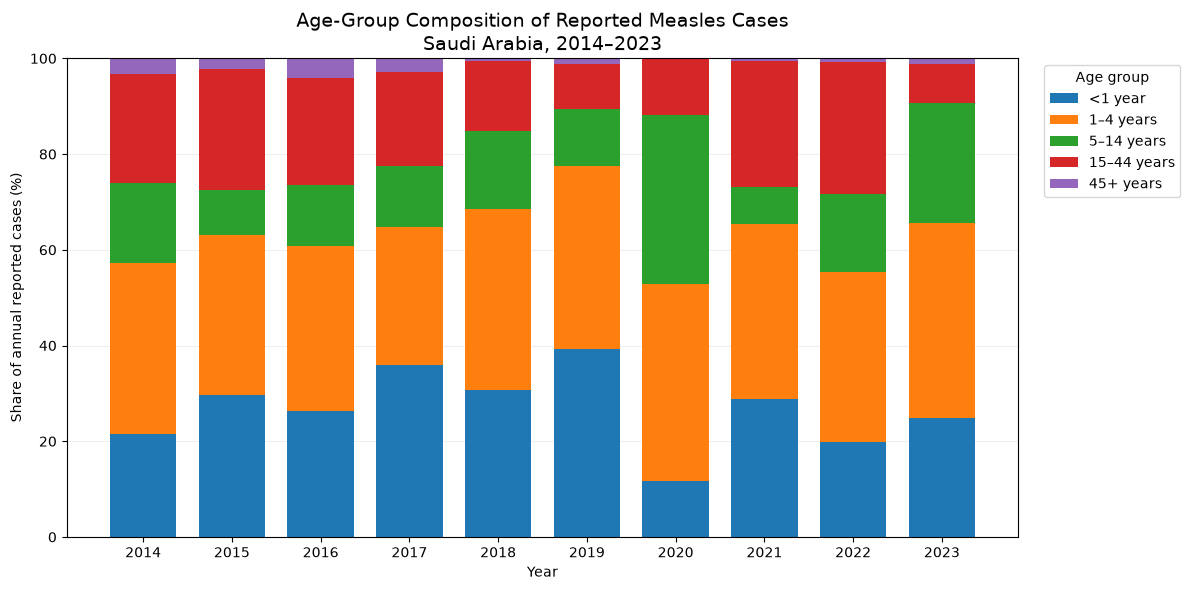

In [7]:

fig, ax = plt.subplots(figsize=(12, 6))

bottom = np.zeros(len(age_percent))

for group in age_order:
    values = age_percent[group].to_numpy()

    ax.bar(
        age_percent.index,
        values,
        bottom=bottom,
        width=0.75,
        label=age_labels[group]
    )

    bottom += values

ax.set_title(
    "Age-Group Composition of Reported Measles Cases\n"
    "Saudi Arabia, 2014–2023",
    fontsize=14
)

ax.set_xlabel("Year")
ax.set_ylabel("Share of annual reported cases (%)")

ax.set_xticks(age_percent.index)
ax.set_ylim(0, 100)

ax.legend(
    title="Age group",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [9]:
################################################
## Annual Reported Measles Cases by Age Group ##

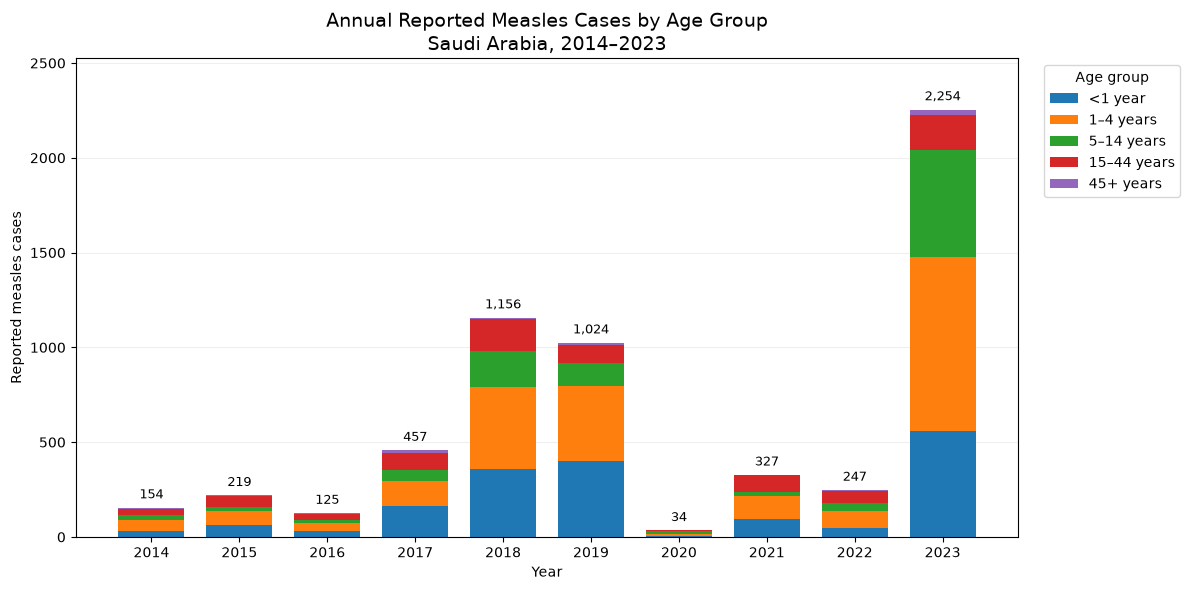

In [10]:

import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(12, 6))

bottom = np.zeros(len(age_counts))

# Stacked bars showing actual reported cases
for group in age_order:

    values = age_counts[group].to_numpy()

    ax.bar(
        age_counts.index,
        values,
        bottom=bottom,
        width=0.75,
        label=age_labels[group]
    )

    bottom += values

# Add total reported cases above each bar
for year, total in zip(age_counts.index, bottom):
    ax.text(
        year,
        total + max(bottom) * 0.015,
        f"{int(total):,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_title(
    "Annual Reported Measles Cases by Age Group\n"
    "Saudi Arabia, 2014–2023",
    fontsize=14
)

ax.set_xlabel("Year")
ax.set_ylabel("Reported measles cases")

ax.set_xticks(age_counts.index)
ax.set_ylim(0, max(bottom) * 1.12)

ax.legend(
    title="Age group",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [11]:

# Compare age-group totals with national annual cases
age_year_totals = age_counts.sum(axis=1)

national_year_totals = (
    annual.set_index("year")["reported_cases"]
)

assert age_year_totals.equals(
    national_year_totals.reindex(age_year_totals.index)
)

print("All annual age-group totals match national totals.")

display(
    age_year_totals.rename("Total reported cases").to_frame()
)


All annual age-group totals match national totals.


,Total reported cases
year,
2014,154
2015,219
2016,125
2017,457
2018,1156
2019,1024
2020,34
2021,327
2022,247


In [12]:
###################################
### 11.3 Age-Group Comparison of Major Measles Reporting Years


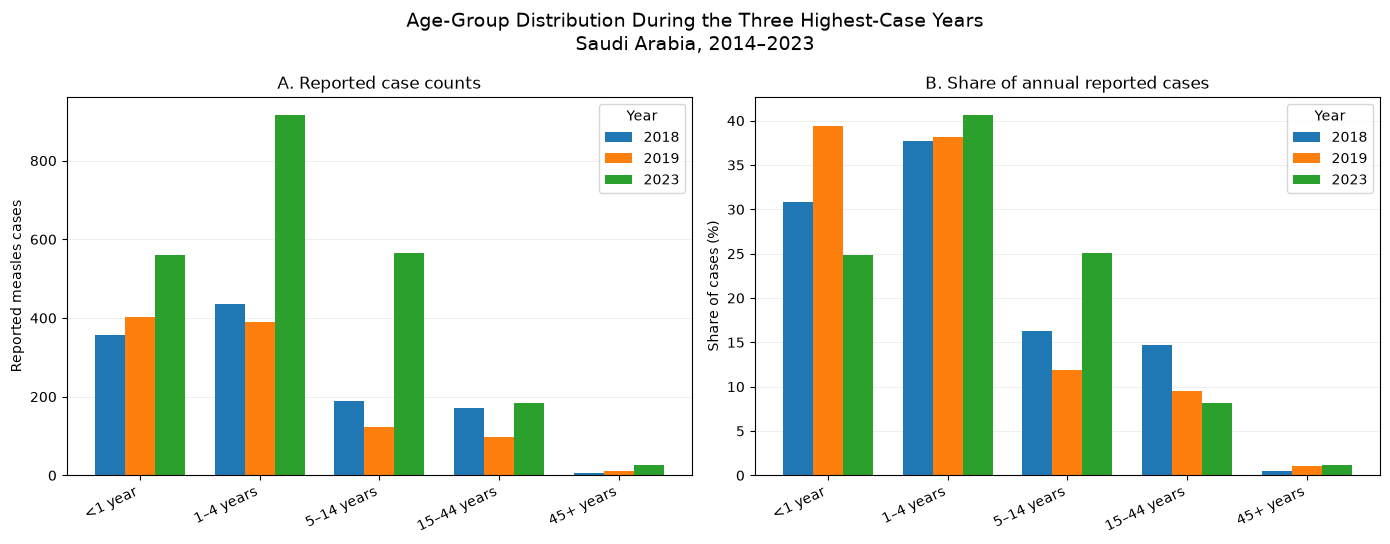

Years compared: [2018, 2019, 2023]


In [13]:

import matplotlib.pyplot as plt
import numpy as np

# Three years with the largest reported national totals
top_years = (
    annual.nlargest(3, "reported_cases")["year"]
    .sort_values()
    .tolist()
)

comparison_counts = age_counts.loc[top_years]
comparison_percent = age_percent.loc[top_years]

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5)
)

x = np.arange(len(age_order))
width = 0.25

# Panel A — Absolute counts
for i, year in enumerate(top_years):
    axes[0].bar(
        x + (i - 1) * width,
        comparison_counts.loc[year, age_order],
        width=width,
        label=str(year)
    )

axes[0].set_title("A. Reported case counts")
axes[0].set_ylabel("Reported measles cases")
axes[0].set_xticks(x)
axes[0].set_xticklabels(
    [age_labels[group] for group in age_order],
    rotation=25,
    ha="right"
)
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)

# Panel B — Percentage composition
for i, year in enumerate(top_years):
    axes[1].bar(
        x + (i - 1) * width,
        comparison_percent.loc[year, age_order],
        width=width,
        label=str(year)
    )

axes[1].set_title("B. Share of annual reported cases")
axes[1].set_ylabel("Share of cases (%)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(
    [age_labels[group] for group in age_order],
    rotation=25,
    ha="right"
)
axes[1].grid(axis="y", alpha=0.2)
axes[1].set_axisbelow(True)

axes[0].legend(title="Year")
axes[1].legend(title="Year")

fig.suptitle(
    "Age-Group Distribution During the Three Highest-Case Years\n"
    "Saudi Arabia, 2014–2023",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("Years compared:", top_years)


In [14]:

age_change = pd.DataFrame({
    "Age group": [age_labels[g] for g in age_order],
    "2019 cases": age_counts.loc[2019, age_order].to_numpy(),
    "2023 cases": age_counts.loc[2023, age_order].to_numpy()
})

age_change["Case difference"] = (
    age_change["2023 cases"] - age_change["2019 cases"]
)

total_difference = age_change["Case difference"].sum()

age_change["Share of total difference (%)"] = (
    age_change["Case difference"] / total_difference * 100
)

assert total_difference == (
    annual.loc[annual["year"] == 2023, "reported_cases"].iloc[0]
    - annual.loc[annual["year"] == 2019, "reported_cases"].iloc[0]
)

display(age_change.round(2))

print("Total case difference:", total_difference)


,Age group,2019 cases,2023 cases,Case difference,Share of total difference (%)
0,<1 year,403,561,158,12.85
1,1–4 years,391,916,525,42.68
2,5–14 years,122,565,443,36.02
3,15–44 years,97,185,88,7.15
4,45+ years,11,27,16,1.30


Total case difference: 1230


In [15]:

from pathlib import Path
import pandas as pd

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Prepare the table for export
export_table = age_change.copy()

# Round the percentage column to 2 decimal places
export_table["Share of total difference (%)"] = (
    export_table["Share of total difference (%)"].round(2)
)

# Export CSV
export_table.to_csv(
    output_dir / "measles_age_group_comparison_2019_2023.csv",
    index=False
)

# Export Excel
export_table.to_excel(
    output_dir / "measles_age_group_comparison_2019_2023.xlsx",
    index=False,
    sheet_name="Age Group Comparison"
)

print("Both files exported successfully.")
print("Total case difference:",
      export_table["Case difference"].sum())

display(export_table)


Both files exported successfully.
Total case difference: 1230


,Age group,2019 cases,2023 cases,Case difference,Share of total difference (%)
0,<1 year,403,561,158,12.85
1,1–4 years,391,916,525,42.68
2,5–14 years,122,565,443,36.02
3,15–44 years,97,185,88,7.15
4,45+ years,11,27,16,1.30


In [18]:
####################################
## ## 12. National Monthly Distribution and Temporal Patterns
####################################

In [19]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

month_order = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Create a year-by-month count table
monthly_counts = (
    monthly.pivot(
        index="year",
        columns="month_number",
        values="reported_cases"
    )
    .reindex(columns=range(1, 13))
    .sort_index()
)

monthly_counts.columns = month_order

# Calculate the percentage of each year's cases
# occurring in each calendar month
monthly_percent = (
    monthly_counts
    .div(monthly_counts.sum(axis=1), axis=0)
    * 100
)

# Validate against the national annual totals
national_totals = annual.set_index("year")["reported_cases"]

assert monthly_counts.shape == (10, 12)
assert not monthly_counts.isna().any().any()

assert (
    monthly_counts.sum(axis=1)
    == national_totals.reindex(monthly_counts.index)
).all()

assert np.allclose(
    monthly_percent.sum(axis=1),
    100
)

print("Monthly case data validated.")

print("\nMonthly reported cases:")
display(monthly_counts)

print("\nWithin-year monthly percentages:")
display(monthly_percent.round(2))


Monthly case data validated.

Monthly reported cases:


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
year,,,,,,,,,,,,
2014,17,20,17,18,16,10,4,7,5,13,13,14
2015,20,6,4,38,54,51,17,15,5,5,4,0
2016,4,9,8,4,7,6,19,23,6,12,9,18
2017,82,84,39,26,17,8,17,13,28,27,53,63
2018,73,105,185,251,169,73,69,34,39,52,51,55
2019,292,424,157,62,19,26,14,13,1,3,12,1
2020,5,8,12,7,1,0,0,0,0,0,0,1
2021,0,1,2,0,3,3,1,1,67,123,96,30
2022,18,3,6,1,10,33,15,39,40,20,27,35



Within-year monthly percentages:


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
year,,,,,,,,,,,,
2014,11.04,12.99,11.04,11.69,10.39,6.49,2.60,4.55,3.25,8.44,8.44,9.09
2015,9.13,2.74,1.83,17.35,24.66,23.29,7.76,6.85,2.28,2.28,1.83,0.00
2016,3.20,7.20,6.40,3.20,5.60,4.80,15.20,18.40,4.80,9.60,7.20,14.40
2017,17.94,18.38,8.53,5.69,3.72,1.75,3.72,2.84,6.13,5.91,11.60,13.79
2018,6.31,9.08,16.00,21.71,14.62,6.31,5.97,2.94,3.37,4.50,4.41,4.76
2019,28.52,41.41,15.33,6.05,1.86,2.54,1.37,1.27,0.10,0.29,1.17,0.10
2020,14.71,23.53,35.29,20.59,2.94,0.00,0.00,0.00,0.00,0.00,0.00,2.94
2021,0.00,0.31,0.61,0.00,0.92,0.92,0.31,0.31,20.49,37.61,29.36,9.17
2022,7.29,1.21,2.43,0.40,4.05,13.36,6.07,15.79,16.19,8.10,10.93,14.17


In [20]:
## export tables


from pathlib import Path
import pandas as pd
import numpy as np

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Prepare monthly case-count table
monthly_counts_export = (
    monthly_counts
    .reset_index()
    .rename(columns={"year": "Year"})
)

# Prepare within-year monthly percentage table
monthly_percent_export = (
    monthly_percent
    .round(4)
    .reset_index()
    .rename(columns={"year": "Year"})
)

# Export separate CSV files
monthly_counts_export.to_csv(
    output_dir / "measles_monthly_case_counts_2014_2023.csv",
    index=False
)

monthly_percent_export.to_csv(
    output_dir / "measles_monthly_case_percentages_2014_2023.csv",
    index=False
)

# Export Excel workbook with two worksheets
excel_path = (
    output_dir / "measles_monthly_distribution_2014_2023.xlsx"
)

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    monthly_counts_export.to_excel(
        writer,
        sheet_name="Monthly Counts",
        index=False
    )

    monthly_percent_export.to_excel(
        writer,
        sheet_name="Monthly Percentages",
        index=False
    )

# Validate exported source tables
assert monthly_counts_export.shape == (10, 13)
assert monthly_percent_export.shape == (10, 13)
assert monthly_counts.to_numpy().sum() == 5997
assert np.allclose(monthly_percent.sum(axis=1), 100)

print("Monthly tables exported successfully.")
print("CSV files: 2")
print("Excel workbook:", excel_path)
print("Total reported cases:", monthly_counts.to_numpy().sum())

display(monthly_counts_export)
display(monthly_percent_export.round(2))


Monthly tables exported successfully.
CSV files: 2
Excel workbook: ../outputs/measles_monthly_distribution_2014_2023.xlsx
Total reported cases: 5997


,Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
0,2014,17,20,17,18,16,10,4,7,5,13,13,14
1,2015,20,6,4,38,54,51,17,15,5,5,4,0
2,2016,4,9,8,4,7,6,19,23,6,12,9,18
3,2017,82,84,39,26,17,8,17,13,28,27,53,63
4,2018,73,105,185,251,169,73,69,34,39,52,51,55
5,2019,292,424,157,62,19,26,14,13,1,3,12,1
6,2020,5,8,12,7,1,0,0,0,0,0,0,1
7,2021,0,1,2,0,3,3,1,1,67,123,96,30
8,2022,18,3,6,1,10,33,15,39,40,20,27,35
9,2023,110,161,400,351,372,243,191,152,96,71,47,60


,Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
0,2014,11.04,12.99,11.04,11.69,10.39,6.49,2.60,4.55,3.25,8.44,8.44,9.09
1,2015,9.13,2.74,1.83,17.35,24.66,23.29,7.76,6.85,2.28,2.28,1.83,0.00
2,2016,3.20,7.20,6.40,3.20,5.60,4.80,15.20,18.40,4.80,9.60,7.20,14.40
3,2017,17.94,18.38,8.53,5.69,3.72,1.75,3.72,2.84,6.13,5.91,11.60,13.79
4,2018,6.31,9.08,16.00,21.71,14.62,6.31,5.97,2.94,3.37,4.50,4.41,4.76
5,2019,28.52,41.41,15.33,6.05,1.86,2.54,1.37,1.27,0.10,0.29,1.17,0.10
6,2020,14.71,23.53,35.29,20.59,2.94,0.00,0.00,0.00,0.00,0.00,0.00,2.94
7,2021,0.00,0.31,0.61,0.00,0.92,0.92,0.31,0.31,20.49,37.61,29.36,9.17
8,2022,7.29,1.21,2.43,0.40,4.05,13.36,6.07,15.79,16.19,8.10,10.93,14.17
9,2023,4.88,7.14,17.75,15.57,16.50,10.78,8.47,6.74,4.26,3.15,2.09,2.66


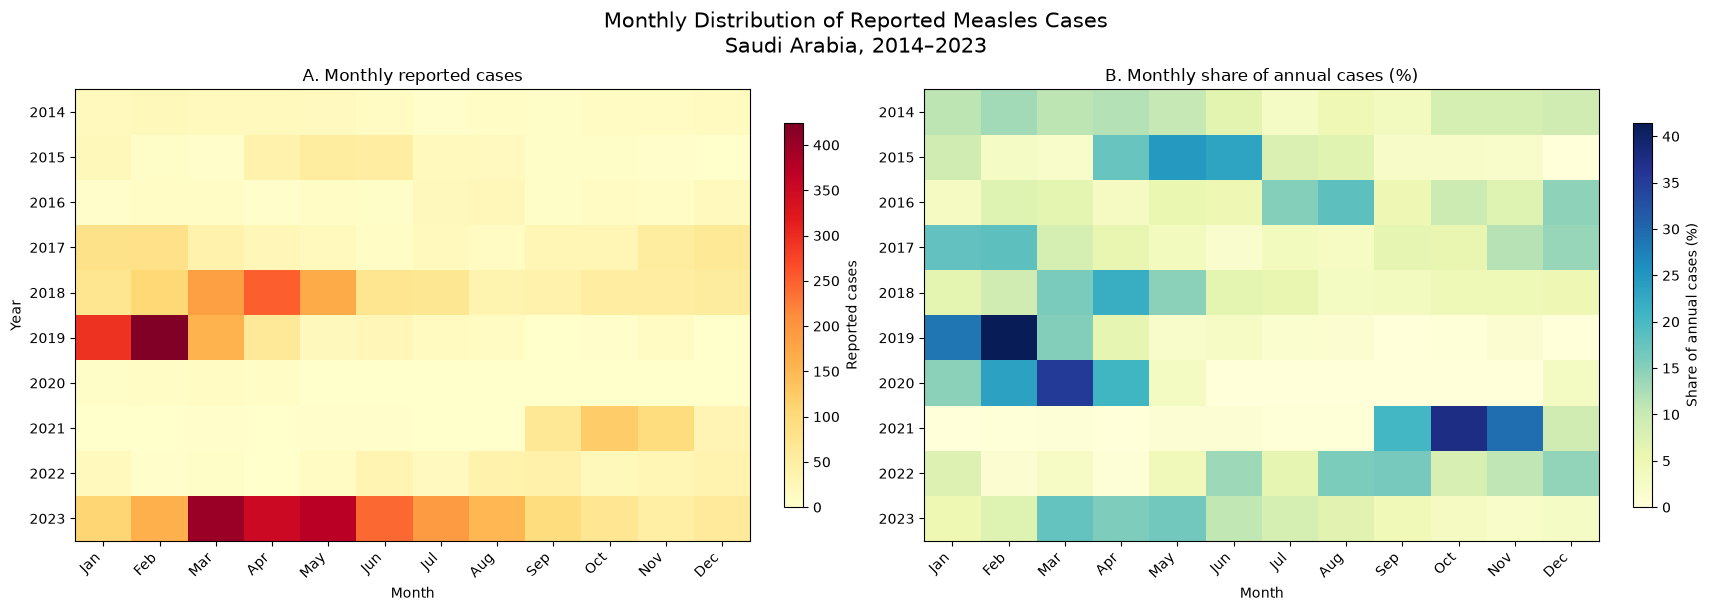

In [21]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 6),
    constrained_layout=True
)

# Panel A — Actual reported cases
im1 = axes[0].imshow(
    monthly_counts.values,
    cmap="YlOrRd",
    aspect="auto"
)

axes[0].set_title("A. Monthly reported cases")
axes[0].set_ylabel("Year")

# Panel B — Monthly percentage of annual cases
im2 = axes[1].imshow(
    monthly_percent.values,
    cmap="YlGnBu",
    aspect="auto"
)

axes[1].set_title("B. Monthly share of annual cases (%)")

# Shared axis formatting
for ax in axes:
    ax.set_xticks(np.arange(12))
    ax.set_xticklabels(month_order, rotation=45, ha="right")
    ax.set_yticks(np.arange(10))
    ax.set_yticklabels(monthly_counts.index)
    ax.set_xlabel("Month")

# Independent colorbars
fig.colorbar(
    im1,
    ax=axes[0],
    shrink=0.85,
    label="Reported cases"
)

fig.colorbar(
    im2,
    ax=axes[1],
    shrink=0.85,
    label="Share of annual cases (%)"
)

fig.suptitle(
    "Monthly Distribution of Reported Measles Cases\n"
    "Saudi Arabia, 2014–2023",
    fontsize=15
)

plt.show()


In [23]:
#####################################
## 12.2 Monthly Peak Timing and Temporal Concentration

In [24]:

import pandas as pd
import numpy as np

results = []

for year, row in monthly_counts.iterrows():

    counts = row.to_numpy(dtype=int)
    annual_total = counts.sum()

    # Single highest-case month
    peak_idx = np.argmax(counts)
    peak_month = month_order[peak_idx]
    peak_cases = counts[peak_idx]

    peak_share = peak_cases / annual_total * 100

    # Three consecutive months with the most cases
    # Windows: Jan-Mar through Oct-Dec
    rolling_3 = np.convolve(
        counts,
        np.ones(3, dtype=int),
        mode="valid"
    )

    max_3_idx = np.argmax(rolling_3)
    max_3_cases = int(rolling_3[max_3_idx])

    max_3_period = (
        f"{month_order[max_3_idx]}–"
        f"{month_order[max_3_idx + 2]}"
    )

    max_3_share = max_3_cases / annual_total * 100

    results.append({
        "Year": year,
        "Annual cases": annual_total,
        "Peak month": peak_month,
        "Peak month cases": peak_cases,
        "Peak month share (%)": peak_share,
        "Peak 3-month period": max_3_period,
        "Peak 3-month cases": max_3_cases,
        "Peak 3-month share (%)": max_3_share
    })

monthly_concentration = pd.DataFrame(results)

# Validate annual totals
assert (
    monthly_concentration["Annual cases"].to_numpy()
    == annual.set_index("year")
             .loc[monthly_concentration["Year"], "reported_cases"]
             .to_numpy()
).all()

assert (
    monthly_concentration["Peak 3-month cases"]
    >= monthly_concentration["Peak month cases"]
).all()

print("Monthly concentration analysis validated.")

display(
    monthly_concentration.round(2)
)


Monthly concentration analysis validated.


,Year,Annual cases,Peak month,Peak month cases,Peak month share (%),Peak 3-month period,Peak 3-month cases,Peak 3-month share (%)
0,2014,154,Feb,20,12.99,Feb–Apr,55,35.71
1,2015,219,May,54,24.66,Apr–Jun,143,65.30
2,2016,125,Aug,23,18.40,Jun–Aug,48,38.40
3,2017,457,Feb,84,18.38,Jan–Mar,205,44.86
4,2018,1156,Apr,251,21.71,Mar–May,605,52.34
5,2019,1024,Feb,424,41.41,Jan–Mar,873,85.25
6,2020,34,Mar,12,35.29,Feb–Apr,27,79.41
7,2021,327,Oct,123,37.61,Sep–Nov,286,87.46
8,2022,247,Sep,40,16.19,Aug–Oct,99,40.08
9,2023,2254,Mar,400,17.75,Mar–May,1123,49.82


In [26]:

from pathlib import Path

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Prepare table for export
export_table = monthly_concentration.copy()

# Round percentage columns
percentage_columns = [
    "Peak month share (%)",
    "Peak 3-month share (%)"
]

export_table[percentage_columns] = (
    export_table[percentage_columns].round(2)
)

# Export CSV
csv_path = (
    output_dir / "measles_monthly_peak_concentration_2014_2023.csv"
)

export_table.to_csv(csv_path, index=False)

# Export Excel
excel_path = (
    output_dir / "measles_monthly_peak_concentration_2014_2023.xlsx"
)

export_table.to_excel(
    excel_path,
    index=False,
    sheet_name="Monthly Concentration"
)

print("Tables exported successfully.")
print("CSV:", csv_path)
print("Excel:", excel_path)

display(export_table)


Tables exported successfully.
CSV: ../outputs/measles_monthly_peak_concentration_2014_2023.csv
Excel: ../outputs/measles_monthly_peak_concentration_2014_2023.xlsx


,Year,Annual cases,Peak month,Peak month cases,Peak month share (%),Peak 3-month period,Peak 3-month cases,Peak 3-month share (%)
0,2014,154,Feb,20,12.99,Feb–Apr,55,35.71
1,2015,219,May,54,24.66,Apr–Jun,143,65.30
2,2016,125,Aug,23,18.40,Jun–Aug,48,38.40
3,2017,457,Feb,84,18.38,Jan–Mar,205,44.86
4,2018,1156,Apr,251,21.71,Mar–May,605,52.34
5,2019,1024,Feb,424,41.41,Jan–Mar,873,85.25
6,2020,34,Mar,12,35.29,Feb–Apr,27,79.41
7,2021,327,Oct,123,37.61,Sep–Nov,286,87.46
8,2022,247,Sep,40,16.19,Aug–Oct,99,40.08
9,2023,2254,Mar,400,17.75,Mar–May,1123,49.82


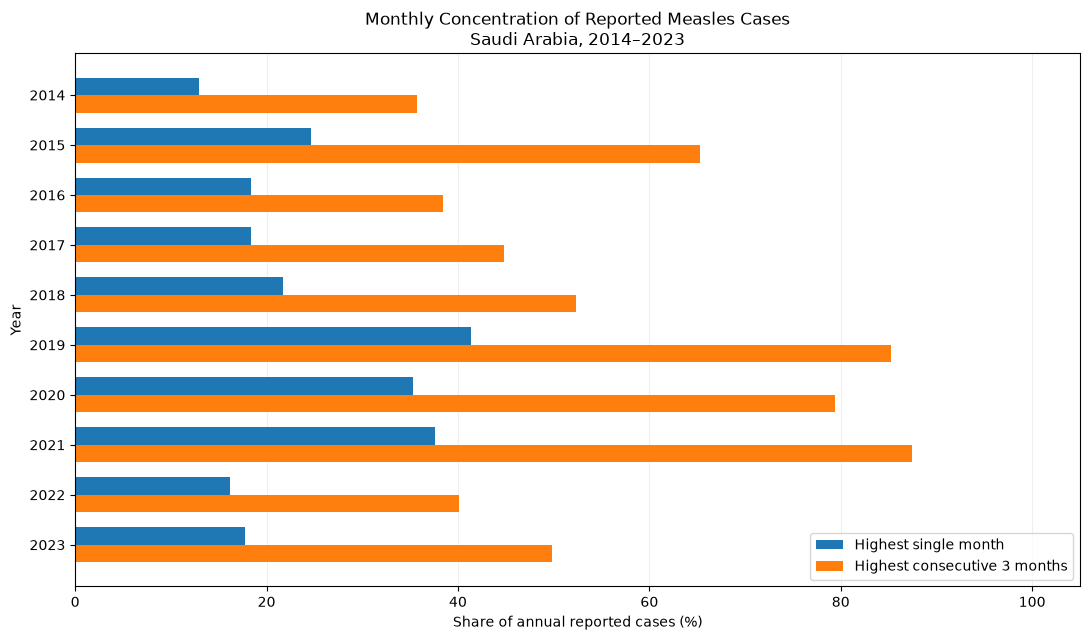

In [25]:

import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(11, 6.5))

y = np.arange(len(monthly_concentration))
height = 0.35

ax.barh(
    y - height / 2,
    monthly_concentration["Peak month share (%)"],
    height=height,
    label="Highest single month"
)

ax.barh(
    y + height / 2,
    monthly_concentration["Peak 3-month share (%)"],
    height=height,
    label="Highest consecutive 3 months"
)

ax.set_yticks(y)
ax.set_yticklabels(
    monthly_concentration["Year"].astype(str)
)

ax.invert_yaxis()
ax.set_xlim(0, 105)

ax.set_xlabel("Share of annual reported cases (%)")
ax.set_ylabel("Year")

ax.set_title(
    "Monthly Concentration of Reported Measles Cases\n"
    "Saudi Arabia, 2014–2023"
)

ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()
